# Bajo peso al nacer en Colombia, 2005-2024 — síntesis del análisis

Fuente: DANE, Estadísticas Vitales (microdatos de nacimientos).

Esta notebook **recalcula** todo con los mismos módulos que `correr.py` (`objN_*.py`): cada objetivo tiene `calcular(celdas)` (tablas), `graficos(r)` (figuras) e `imprimir(r)` (resumen del log). No escribe archivos; para regenerar los xlsx, png y logs se usa `python correr.py`.

Las celdas de conteos salen de la caché parquet de `3.0 Datos/python_v2/procesados/celdas/`, así que correr todo tarda unos 20 segundos.

In [1]:
import pandas as pd

import comun_bpn as cb
import obj1_evolucion as o1
import obj2_desigualdades as o2
import obj3_educacion as o3
import obj4_concentracion as o4

%matplotlib inline
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)

celdas = cb.cargar_celdas()

  2005: celdas en caché (24,378)
  2006: celdas en caché (23,899)
  2007: celdas en caché (24,273)
  2008: celdas en caché (49,242)
  2009: celdas en caché (46,180)
  2010: celdas en caché (43,810)
  2011: celdas en caché (40,038)
  2012: celdas en caché (37,754)
  2013: celdas en caché (36,173)
  2014: celdas en caché (35,383)
  2015: celdas en caché (35,015)
  2016: celdas en caché (34,622)
  2017: celdas en caché (34,930)
  2018: celdas en caché (35,633)
  2019: celdas en caché (36,631)
  2020: celdas en caché (37,383)
  2021: celdas en caché (37,250)
  2022: celdas en caché (35,426)
  2023: celdas en caché (33,119)
  2024: celdas en caché (31,064)


## Objetivo 1. Evolución y distribución del BPN

Prevalencia nacional cruda (IC 95 % de Wilson) y estandarizada por edad materna (método directo; población estándar: nacidos 2005-2024 con peso y edad conocidos). Cambio porcentual anual (APC) con Poisson y errores robustos.

In [2]:
r1 = o1.calcular(celdas)
r1["Nacional"][["anio", "nacidos_vivos", "pct_sin_peso", "pct_bpn",
                 "li_bpn", "ls_bpn", "pct_bpn_term"]]

,anio,nacidos_vivos,pct_sin_peso,pct_bpn,li_bpn,ls_bpn,pct_bpn_term
0,2005,"719,968.000",2.175,8.286,8.222,8.351,2.827
1,2006,"714,450.000",1.608,8.577,8.512,8.643,2.947
2,2007,"709,253.000",1.146,8.696,8.630,8.762,2.914
3,2008,"715,453.000",0.961,8.851,8.785,8.918,2.815
4,2009,"699,775.000",0.695,9.079,9.011,9.146,2.884
5,2010,"654,627.000",0.507,9.086,9.017,9.156,2.872
6,2011,"665,499.000",0.464,9.052,8.983,9.121,2.693
7,2012,"676,835.000",0.537,8.983,8.915,9.051,2.557
8,2013,"658,835.000",0.568,8.973,8.904,9.043,2.357
9,2014,"669,137.000",0.435,8.755,8.687,8.823,2.142


In [3]:
r1["Nacional_estandarizada"]

,anio,n,casos,pct_cruda,pct_estand,li_estand,ls_estand
0,2005,"702,229.000","58,208.000",8.289,8.268,8.203,8.332
1,2006,"701,037.000","60,127.000",8.577,8.555,8.489,8.620
2,2007,"699,127.000","60,803.000",8.697,8.677,8.611,8.743
3,2008,"703,653.000","62,297.000",8.853,8.836,8.769,8.902
4,2009,"690,846.000","62,755.000",9.084,9.067,8.999,9.135
5,2010,"648,721.000","58,996.000",9.094,9.079,9.009,9.149
6,2011,"661,825.000","59,926.000",9.055,9.045,8.976,9.114
7,2012,"673,167.000","60,469.000",8.983,8.966,8.898,9.034
8,2013,"655,069.000","58,782.000",8.973,8.966,8.897,9.035
9,2014,"666,224.000","58,326.000",8.755,8.754,8.686,8.822


In [4]:
r1["APC"].query("dpto_res == 0")

,dpto_res,departamento,periodo,apc,li,ls,p,n_anios
0,0,Colombia,2005-2024,1.089,0.711,1.469,0.000,20
1,0,Colombia,2005-2021,0.612,0.356,0.869,0.000,17


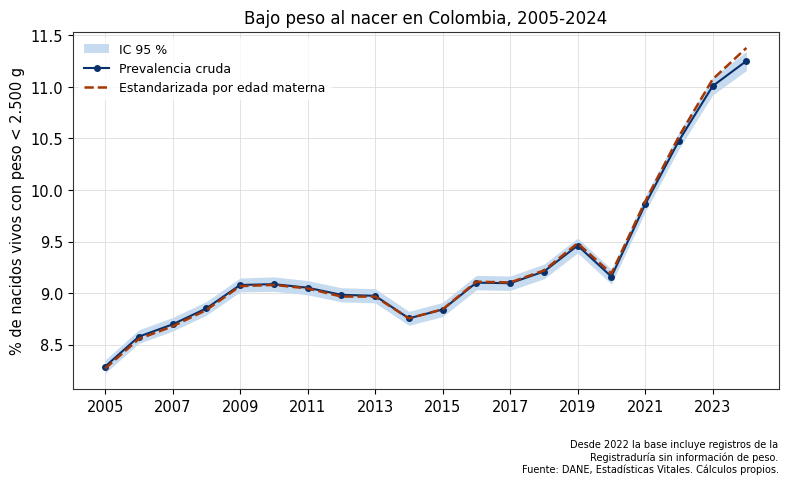

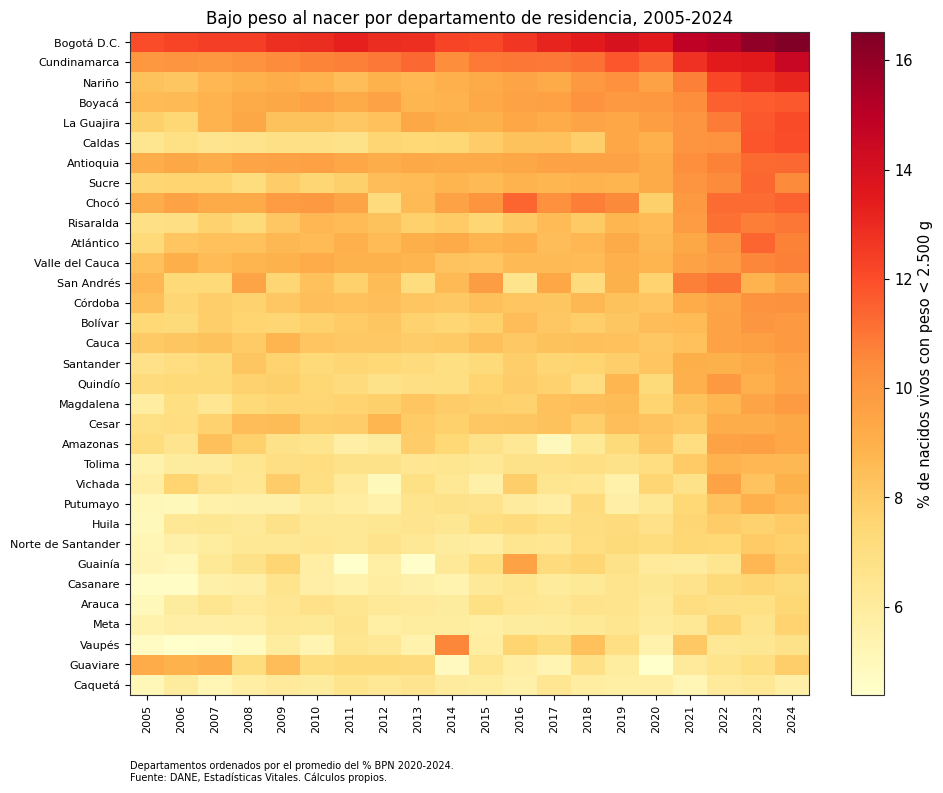

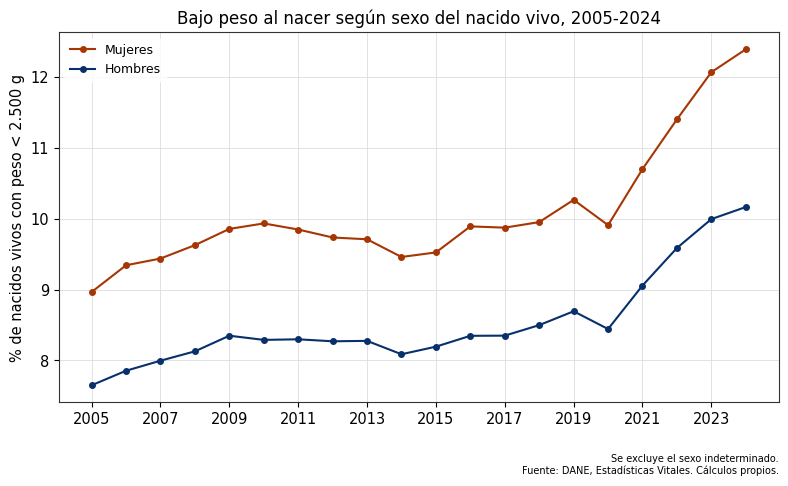

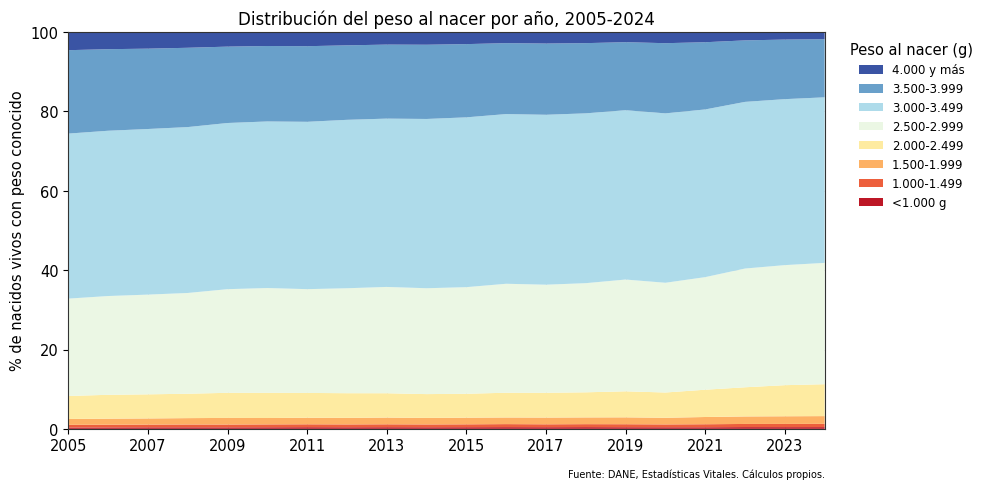

In [5]:
g1 = o1.graficos(r1)

Departamentos con mayor proporción de nacidos sin peso registrado (quinquenio 4 = 2020-2024):

In [6]:
r1["Calidad_registro_peso"].sort_values("pct_sin_peso4", ascending=False).head(8)

quinq,dpto_res,departamento,pct_sin_peso1,pct_sin_peso2,pct_sin_peso3,pct_sin_peso4
31,97,Vaupés,10.224,17.386,17.047,31.515
32,99,Vichada,4.846,19.948,13.901,28.796
28,91,Amazonas,5.143,4.728,3.916,14.650
11,27,Chocó,2.729,3.049,10.719,13.454
29,94,Guainía,0.511,0.137,0.702,5.234
24,81,Arauca,13.839,7.246,4.317,3.800
13,44,La Guajira,3.870,0.309,0.102,3.298
19,66,Risaralda,0.357,2.824,2.345,2.961


**Interpretación:** _(por escribir)_

## Objetivo 2. Desigualdades departamentales (RP/DP)

Razones y diferencias de prevalencias frente a la referencia elegible (menor prevalencia entre departamentos con suficientes nacidos con peso y ≤5 % sin peso), por quinquenio y año. Medidas resumen: Theil, MLD, PAR/PAF y casos en exceso.

In [7]:
r2 = o2.calcular(celdas)
r2["Medidas_resumen"].query("tipo == 'Quinquenio'")

,periodo,tipo,mu,ref,dpto_ref,par,paf,exceso,theil,mld,pmax,dpto_max,pmin,dpto_min,rt_ext,dt_ext,rt_ext_el,dt_ext_el
0,2005-2009,Quinquenio,8.695,5.355,Putumayo,3.341,38.421,"117,154.873",25.942,25.854,12.389,Bogotá D.C.,4.875,Vaupés,2.541,7.514,2.314,7.035
1,2010-2014,Quinquenio,8.966,5.620,Casanare,3.347,37.323,"110,608.769",24.843,24.419,12.856,Bogotá D.C.,5.290,Guainía,2.430,7.566,2.288,7.236
2,2015-2019,Quinquenio,9.131,5.912,Caquetá,3.219,35.257,"103,786.410",22.251,21.843,13.018,Bogotá D.C.,5.912,Caquetá,2.202,7.106,2.202,7.106
3,2020-2024,Quinquenio,10.270,5.799,Caquetá,4.472,43.540,"121,716.392",23.797,23.366,15.129,Bogotá D.C.,5.799,Caquetá,2.609,9.331,2.609,9.331


In [8]:
r2["RP_DP_ancho"].head(10)

,dpto_res,departamento,rt1,rt2,rt3,rt4,dt1,dt2,dt3,dt4,rt_prom,dt_prom
0,11,Bogotá D.C.,2.314,2.288,2.202,2.609,7.035,7.236,7.106,9.331,2.353,7.677
1,25,Cundinamarca,1.898,1.923,1.887,2.248,4.806,5.188,5.242,7.234,1.989,5.618
2,27,Chocó,1.752,1.591,1.794,1.761,4.029,3.321,4.695,4.415,1.725,4.115
3,15,Boyacá,1.666,1.638,1.642,1.895,3.566,3.584,3.794,5.192,1.710,4.034
4,5,Antioquia,1.738,1.661,1.597,1.809,3.954,3.716,3.529,4.694,1.702,3.973
5,52,Nariño,1.613,1.566,1.625,1.988,3.280,3.182,3.692,5.730,1.698,3.971
6,44,La Guajira,1.563,1.540,1.572,1.866,3.014,3.037,3.383,5.019,1.635,3.613
7,76,Valle del Cauca,1.633,1.567,1.454,1.699,3.388,3.189,2.682,4.053,1.588,3.328
8,8,Atlántico,1.529,1.584,1.499,1.714,2.834,3.281,2.950,4.142,1.582,3.302
9,70,Sucre,1.410,1.464,1.490,1.775,2.196,2.609,2.895,4.493,1.535,3.048


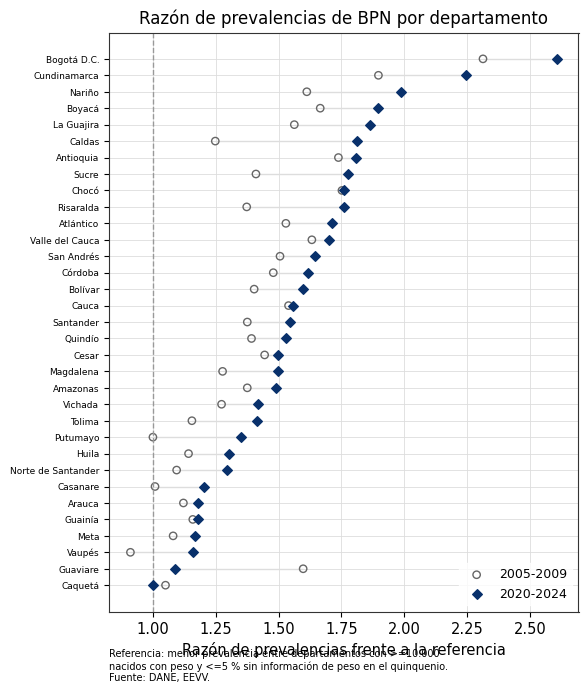

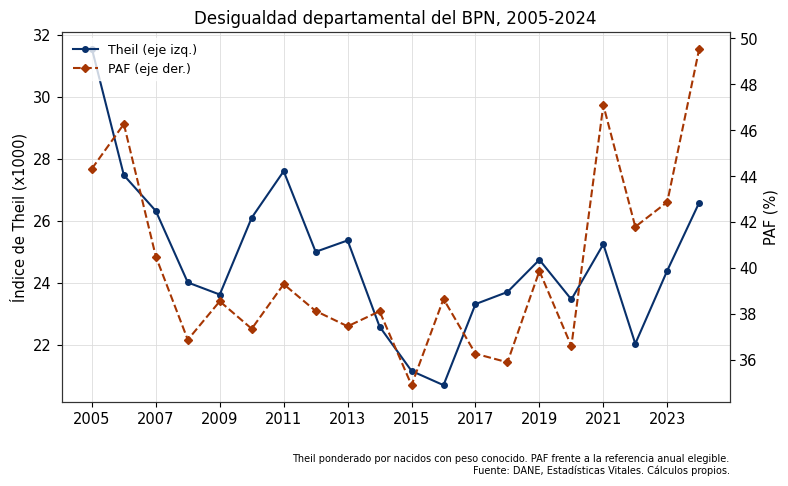

In [9]:
g2 = o2.graficos(r2)

**Interpretación:** _(por escribir)_

## Objetivo 3. Educación de la madre, régimen de afiliación y BPN

Prevalencias estandarizadas por edad y razones de prevalencia con Poisson (exposición: nacidos con peso; errores agrupados por departamento), modelos M0 a M5. RII y SII por educación con ridit por año. El régimen solo es comparable desde 2008.

In [10]:
r3 = o3.calcular(celdas)
r3["Prevalencias"]

,grupo,categoria,periodo,n,casos,pct_cruda,pct_estand,li_estand,ls_estand
0,Nivel educativo,Ninguno o preescolar,2005-2024,"191,869.000","18,934.000",9.868,9.808,9.669,9.948
1,Nivel educativo,Primaria,2005-2024,"2,087,415.000","181,600.000",8.700,8.512,8.474,8.550
2,Nivel educativo,Secundaria o media,2005-2024,"7,422,867.000","682,039.000",9.188,9.207,9.185,9.228
3,Nivel educativo,Superior,2005-2024,"2,648,625.000","252,389.000",9.529,9.590,9.535,9.645
4,Nivel educativo,Ninguno o preescolar,2008-2024,"147,682.000","14,798.000",10.020,9.957,9.796,10.118
5,Nivel educativo,Primaria,2008-2024,"1,559,072.000","138,976.000",8.914,8.703,8.658,8.747
6,Nivel educativo,Secundaria o media,2008-2024,"6,230,667.000","580,577.000",9.318,9.343,9.319,9.366
7,Nivel educativo,Superior,2008-2024,"2,366,755.000","227,200.000",9.600,9.660,9.599,9.720
8,Régimen,"Contributivo, excepción o especial",2008-2024,"4,379,690.000","431,863.000",9.861,9.962,9.932,9.992
9,Régimen,Subsidiado,2008-2024,"5,522,817.000","488,282.000",8.841,8.792,8.768,8.816


In [11]:
r3["RP_modelos"][r3["RP_modelos"]["modelo"].str.startswith(("M3", "M4", "M5"))]

,modelo,variable,categoria,rp,li,ls,p,n_obs,n_clust
13,M3 Educación + régimen + edad + año,educ4,Ninguno o preescolar,1.105,1.022,1.195,0.012,88053,33
14,M3 Educación + régimen + edad + año,educ4,Primaria,0.992,0.954,1.031,0.672,88053,33
15,M3 Educación + régimen + edad + año,educ4,Secundaria o media,1.014,0.983,1.047,0.383,88053,33
16,M3 Educación + régimen + edad + año,regimen,Subsidiado,0.871,0.784,0.966,0.009,88053,33
17,M3 Educación + régimen + edad + año,regimen,No asegurado,1.019,0.977,1.063,0.373,88053,33
18,M3 Educación + régimen + edad + año,edad6,Menos de 20,1.168,1.131,1.205,0.000,88053,33
19,M3 Educación + régimen + edad + año,edad6,25-29,0.944,0.938,0.950,0.000,88053,33
20,M3 Educación + régimen + edad + año,edad6,30-34,1.006,0.993,1.019,0.366,88053,33
21,M3 Educación + régimen + edad + año,edad6,35-39,1.167,1.145,1.189,0.000,88053,33
22,M3 Educación + régimen + edad + año,edad6,40 y más,1.439,1.405,1.474,0.000,88053,33


In [12]:
r3["RII_SII_educacion"]

,periodo,indice,p,valor,li,ls
0,2005-2024,RII,0.057,0.903,0.814,1.003
1,2005-2024,SII (pp),0.088,-0.930,-1.999,0.140
2,2008-2024,RII,0.069,0.910,0.822,1.007
3,2008-2024,SII (pp),0.101,-0.877,-1.924,0.170


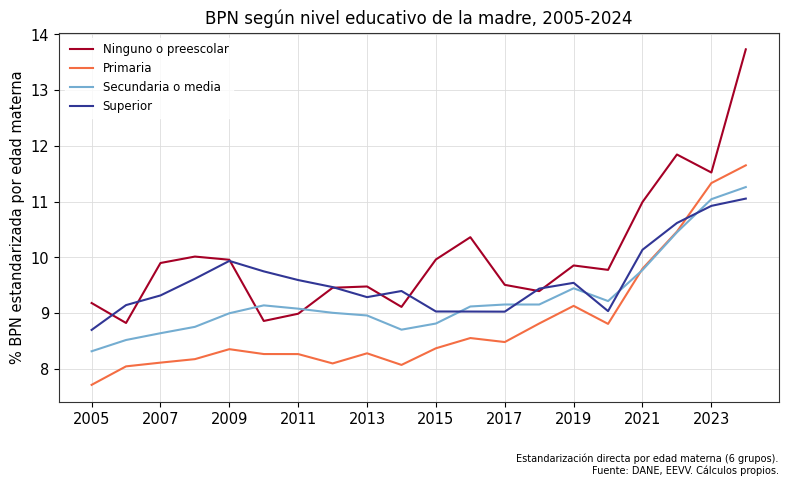

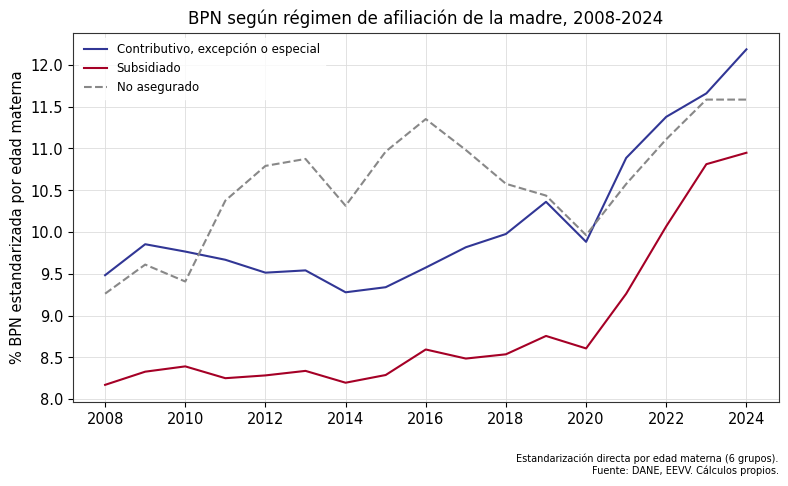

In [13]:
g3 = o3.graficos(r3)

**Interpretación:** _(por escribir)_

## Objetivo 4. Índice de concentración entre departamentos

Índices C, W y E por regresión conveniente (Kakwani et al., 1997), ponderados por nacidos y ordenando los departamentos por % de madres no afiliadas al régimen contributivo. Inferencia: bootstrap por departamento (1.000 réplicas; pareado para la diferencia entre trienios). Estandarización indirecta por altitud y edad materna.

In [14]:
r4 = o4.calcular(celdas)
r4["C_trienios"]

No se encontró la plantilla NBI/IPM (3.0 Datos/nbi_ipm_departamentos.csv); se omite la validación.


,variante,trienio,N,mu,C,se_reg,se_bs,li,ls,p,W,se_W,E,se_E
0,Principal,2008-2010,33,9.004,0.089,0.031,0.038,0.014,0.163,0.019,0.098,0.042,0.032,0.015
1,Principal,2022-2024,33,10.878,0.081,0.032,0.036,0.009,0.152,0.027,0.090,0.041,0.035,0.017
2,Estandarizado por altitud y edad materna,2008-2010,33,9.009,0.023,0.008,0.010,0.003,0.042,0.026,0.025,0.011,0.008,0.004
3,Estandarizado por altitud y edad materna,2022-2024,33,10.878,0.012,0.011,0.013,-0.013,0.037,0.351,0.013,0.014,0.005,0.006
4,Sin Bogotá D.C.,2008-2010,32,8.251,0.030,0.015,0.017,-0.002,0.063,0.066,0.033,0.018,0.010,0.006
5,Sin Bogotá D.C.,2022-2024,32,10.187,0.034,0.022,0.023,-0.011,0.080,0.141,0.038,0.026,0.014,0.010
6,Sin departamentos de altiplano,2008-2010,29,8.022,0.029,0.014,0.015,0.000,0.058,0.050,0.031,0.016,0.009,0.005
7,Sin departamentos de altiplano,2022-2024,29,9.793,0.019,0.016,0.020,-0.019,0.057,0.330,0.021,0.022,0.007,0.008
8,Sin departamentos con >5 % sin peso,2008-2010,30,9.025,0.088,0.031,0.038,0.013,0.163,0.022,0.097,0.042,0.032,0.015
9,Sin departamentos con >5 % sin peso,2022-2024,28,10.890,0.082,0.033,0.035,0.014,0.151,0.018,0.093,0.040,0.036,0.017


In [15]:
r4["Diferencia_trienios"]

,variante,C1,C2,dif,se_bs,li,ls,p
0,Principal,0.089,0.081,-0.008,0.014,-0.036,0.020,0.558
1,Estandarizado por altitud y edad materna,0.023,0.012,-0.010,0.010,-0.029,0.008,0.276
2,Sin Bogotá D.C.,0.030,0.034,0.004,0.016,-0.027,0.035,0.816
3,Sin departamentos de altiplano,0.029,0.019,-0.010,0.015,-0.039,0.019,0.509
4,Sin departamentos con >5 % sin peso,0.090,0.081,-0.008,0.015,-0.038,0.021,0.578
5,Cota inferior (faltantes sin BPN),0.092,0.084,-0.008,0.015,-0.037,0.021,0.583
6,Cota superior (faltantes con BPN),0.054,0.050,-0.003,0.017,-0.037,0.031,0.844
7,BPN a término en partos únicos,0.080,0.018,-0.062,0.042,-0.144,0.020,0.137
8,Ordenamiento: % subsidiado,0.090,0.081,-0.009,0.015,-0.038,0.021,0.563
9,Ordenamiento: % baja escolaridad,0.087,0.083,-0.005,0.013,-0.031,0.022,0.732


In [16]:
r4["C_anual_bootstrap"].query("variante == 'Principal'")

,anio,variante,C,se_bs,li,ls,li_p,ls_p,W,se_W,E,se_E,p
0,2008,Principal,0.088,0.036,0.017,0.159,0.008,0.126,0.097,0.040,0.031,0.014,0.015
2,2009,Principal,0.087,0.039,0.011,0.163,-0.003,0.124,0.096,0.043,0.032,0.015,0.024
4,2010,Principal,0.093,0.038,0.018,0.168,-0.000,0.128,0.102,0.043,0.034,0.015,0.016
6,2011,Principal,0.099,0.041,0.018,0.179,0.005,0.140,0.108,0.045,0.036,0.016,0.016
8,2012,Principal,0.089,0.040,0.010,0.167,-0.001,0.126,0.097,0.044,0.032,0.016,0.027
10,2013,Principal,0.090,0.039,0.014,0.166,-0.004,0.125,0.099,0.043,0.032,0.015,0.020
12,2014,Principal,0.078,0.036,0.008,0.148,-0.007,0.114,0.086,0.039,0.027,0.013,0.029
14,2015,Principal,0.073,0.037,0.002,0.145,-0.017,0.109,0.080,0.040,0.026,0.014,0.045
16,2016,Principal,0.077,0.035,0.008,0.146,-0.009,0.112,0.084,0.039,0.028,0.014,0.029
18,2017,Principal,0.083,0.037,0.010,0.156,-0.007,0.121,0.091,0.041,0.030,0.015,0.026


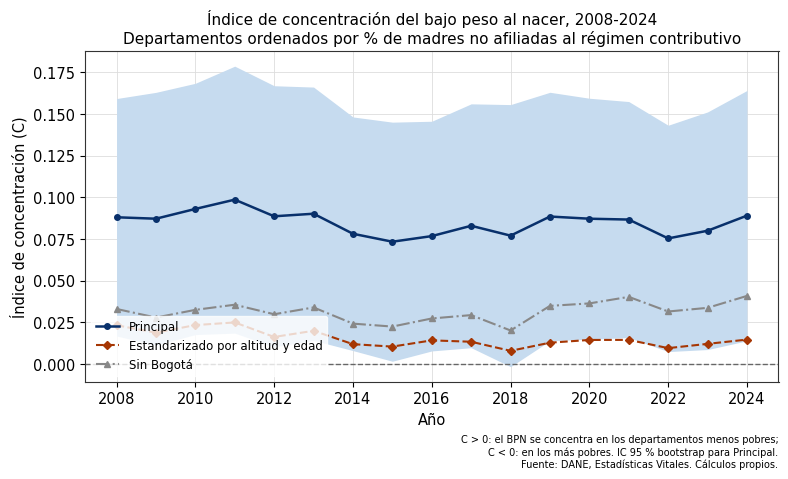

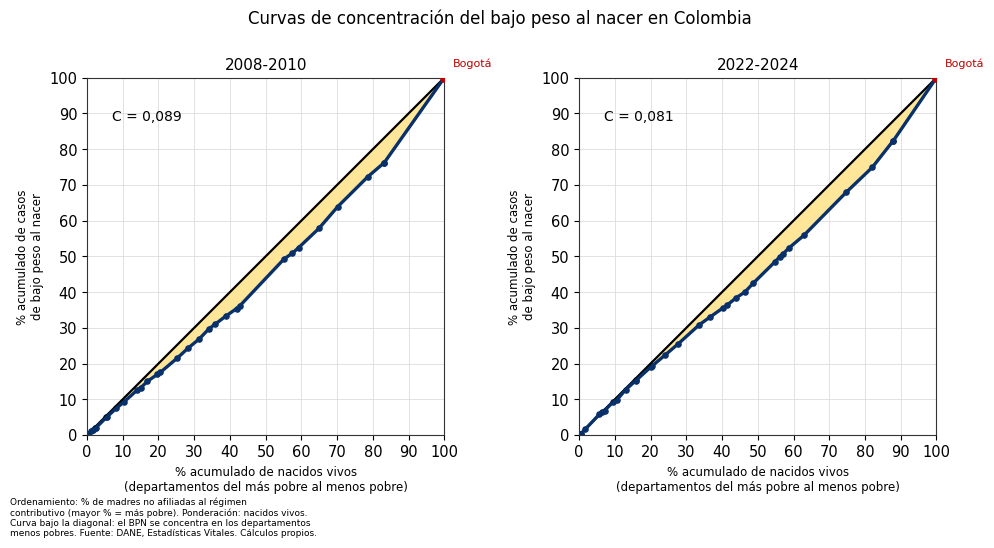

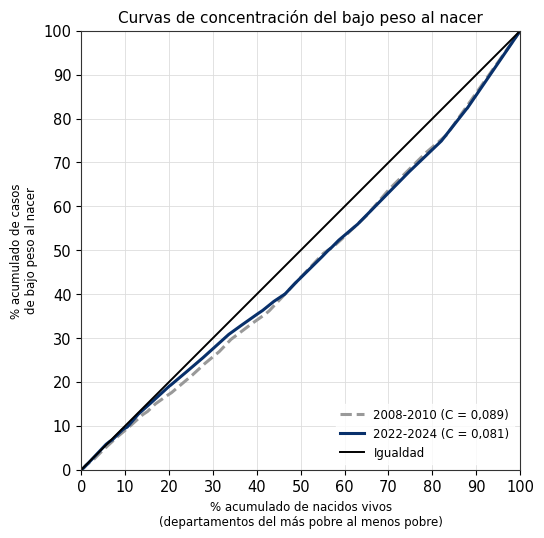

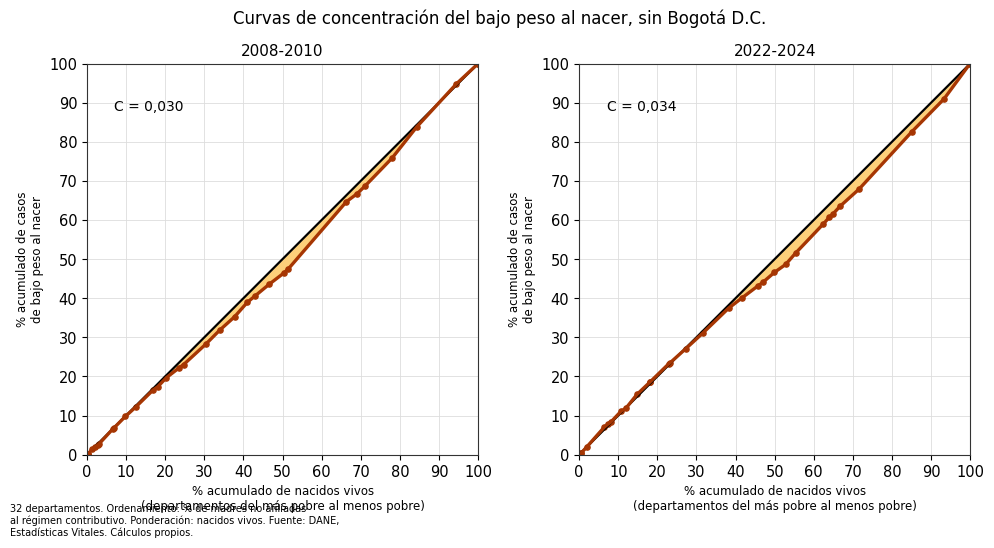

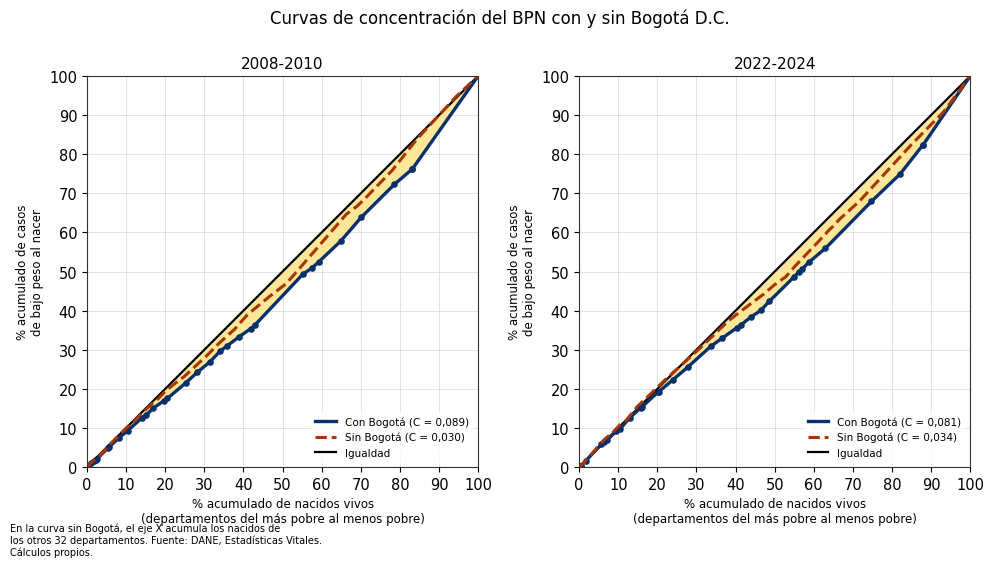

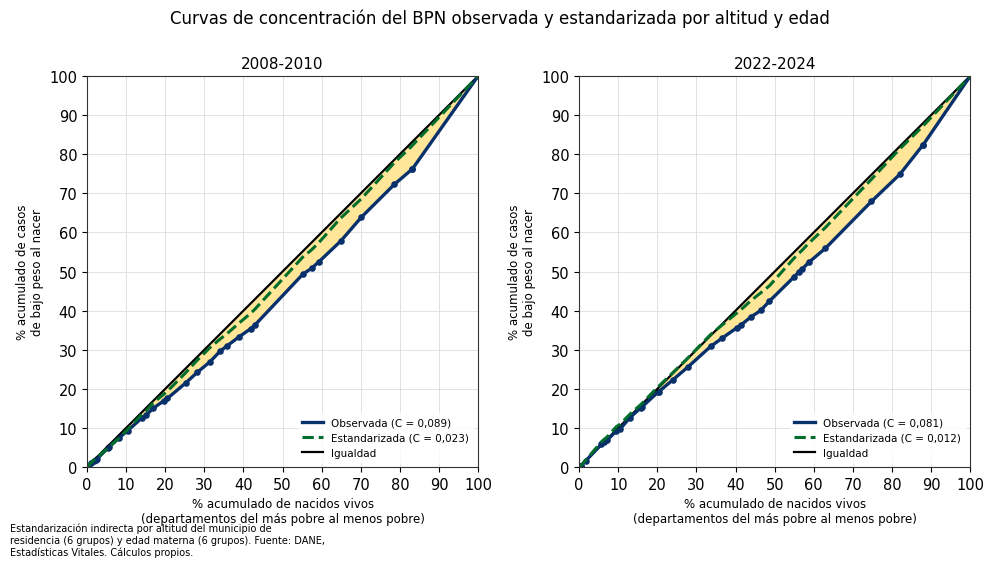

In [17]:
g4 = o4.graficos(r4)

**Interpretación:** _(por escribir)_

## Notas de replicación

- Las semillas del bootstrap hacen que los resultados sean reproducibles entre corridas de Python.
- La validación del ordenamiento contra NBI/IPM solo aparece si existe `3.0 Datos/nbi_ipm_departamentos.csv`.